## **ToF Imaging**

A **time-of-flight camera (ToF camera)** is a range imaging camera system for measuring distances between the camera and the subject for each point of the image based on time-of-flight (the round trip time of an artificial light signal, as provided by a laser or an LED). Laser-based time-of-flight cameras are part of a broader class of scannerless LIDAR, in which the entire scene is captured with each laser pulse, as opposed to point-by-point with a laser beam such as in scanning LIDAR systems.

The task involves **classifying the images into two classes**: background and robot.

The dataset [Miniature mobile robot detection using an utra-low resolution time-of-flight sensor](https://ieee-dataport.org/documents/miniature-mobile-robot-detection-using-ultra-low-resolution-time-flight-sensor-dataset) is composed of ToF depth images acquired with the [ST VL53L5CX ToF sensor](https://www.st.com/en/imaging-and-photonics-solutions/vl53l5cx.html) and sampled by a miniature mobile robot navigating in a sand-like terrain. Each image has a resolution of 8x8 pixels. It comprises a total of 4.150 samples, with 2.062 samples belonging to the background class and 2.088 samples to the Robot class. The bit depth is 8 bits per pixel, where each pixel value represents the depth information.

# **1. Setup and Imports**

## **Environment & Library Versions**

This notebook was developed and tested using the following primary library versions and GPU compute environment. While other versions might work, compatibility is not guaranteed. It is recommended to use versions close to these for best results:

*   **Python:** 3.10.x
*   **TensorFlow:** 2.10.x **(GPU-enabled build)**
*   **NVIDIA CUDA:** 11.2
*   **NVIDIA cuDNN:** 8.1.1.33 (or compatible with CUDA 11.2 & TF 2.10)
*   **Larq:** 0.13.x
*   **Larq Compute Engine:** 0.7.x (or compatible with Larq 0.13.x)
*   **NumPy:** 1.23.x or later
*   **scikit-learn:** 1.2.x or later
*   **Matplotlib:** 3.6.x or later
*   **Seaborn:** 0.12.x or later
*   **Tabulate:** 0.9.x or later
*   **(Optional - Windows Hardware Info):** `WMI` 1.5.x
*   **(Optional - OpenGL Hardware Info):** `pyglet` 1.5.x or 2.0.x

*You can use the first code cell in this notebook to install the Python libraries using `pip`. CUDA and cuDNN require separate installation from NVIDIA, compatible with your GPU driver and TensorFlow version.*

In [1]:
import sys
# Using sys.executable ensures pip installs into the kernel's environment
!{sys.executable} -m pip install -q numpy matplotlib seaborn tabulate scikit-learn WMI pyglet tensorflow larq larq-compute-engine

print("Required packages install command executed.")
print("\n*************************************************************************")
print("IMPORTANT: Please RESTART THE KERNEL now for the changes to take effect.")
print("*************************************************************************")

Required packages install command executed.

*************************************************************************
IMPORTANT: Please RESTART THE KERNEL now for the changes to take effect.
*************************************************************************


In [2]:
# Core Libraries
import os
import sys
import platform
import subprocess
import re
import urllib.request
import zipfile
import time
import random
import pathlib
import traceback

# Data Handling & ML
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate
import sklearn
import sklearn.datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)

# Hardware Info (Optional, requires pip install WMI pyglet)
try:
    import wmi
except ImportError:
    print("WMI not found (only needed for detailed CPU/GPU info on Windows)")
try:
    import pyglet
    import pyglet.gl
except ImportError:
     print("pyglet not found (only needed for OpenGL GPU info fallback)")

# TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.losses import binary_crossentropy

# Larq (for BNNs)
import larq as lq
import larq_compute_engine as lce

# Profiler (for GFLOPS)
from tensorflow.python.profiler.option_builder import ProfileOptionBuilder
from tensorflow.python.profiler.model_analyzer import profile

In [3]:
# Print key library versions
print("--- Key Library Versions ---")
print(f"Python:       {platform.python_version()}")
print(f"NumPy:        {np.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print(f"TensorFlow:   {tf.__version__}")
print(f"Larq:         {lq.__version__}")
print(f"Larq Compute: {lce.__version__}")
print(f"Matplotlib:   {plt.matplotlib.__version__}")
print(f"Seaborn:      {sns.__version__}")
print("--------------------------")

--- Key Library Versions ---
Python:       3.10.16
NumPy:        1.26.4
Scikit-learn: 1.6.1
TensorFlow:   2.10.0
Larq:         0.13.3
Larq Compute: 0.16.0
Matplotlib:   3.10.1
Seaborn:      0.13.2
--------------------------


# **2. Hardware Information**

## CPU Info

In [4]:
# Check for WMI before running
if 'wmi' in sys.modules:
    try:
        print("--- CPU Information (via WMI) ---")
        def get_cpu_info():
            c = wmi.WMI()
            for cpu in c.Win32_Processor():
                print(f"{'MaxClockSpeed':<15} {'Name':<38} {'NumberOfCores'}")
                print(f"{cpu.MaxClockSpeed:<15} {cpu.Name:<38} {cpu.NumberOfCores}")
        get_cpu_info()
    except Exception as e:
        print(f"Could not get CPU info via WMI: {e}")
else:
    print("WMI module not available. Skipping CPU info.")

--- CPU Information (via WMI) ---
MaxClockSpeed   Name                                   NumberOfCores
2900            13th Gen Intel(R) Core(TM) i7-13700H   14


## GPU Info

In [5]:
# Cell: Check for GPU Availability (Platform Agnostic Attempt)

print(f"TensorFlow Version: {tf.__version__}")
print(f"Python Version: {sys.version}")
print(f"Platform: {platform.system()} ({platform.release()})")

# --- TensorFlow GPU Detection ---
print("\n--- TensorFlow GPU Detection ---")
gpus_tf = tf.config.list_physical_devices('GPU')
if gpus_tf:
    print("TensorFlow detected the following GPU(s):")
    try:
        # Attempt to set memory growth (might fail if already initialized)
        for gpu in gpus_tf:
            tf.config.experimental.set_memory_growth(gpu, True)
            print(f"- {gpu}")
        print("Memory growth set where possible (RuntimeError if already initialized is common).")
    except RuntimeError as e:
        print(f"RuntimeError during memory growth setup: {e}")
        print("GPU detected by TF, but memory growth could not be set (may be okay).")
else:
    print("No GPU detected by TensorFlow. CPU will be used by TF.")

# --- Attempt to Identify System GPU Hardware ---
print("\n--- System Hardware GPU Identification ---")
system = platform.system()
gpu_details_found = False

# Method 1: WMI (Windows Only)
if system == "Windows":
    print("Attempting WMI query (Windows)...")
    if 'wmi' in sys.modules:
        try:
            c = wmi.WMI()
            wql = "SELECT Name, AdapterRAM FROM Win32_VideoController"
            gpu_info_wmi = c.query(wql)
            if gpu_info_wmi:
                print("WMI Video Controller Info:")
                for i, gpu in enumerate(gpu_info_wmi):
                    ram_mb = int(gpu.AdapterRAM) / (1024**2) if gpu.AdapterRAM else "N/A"
                    print(f" - Device {i}: {gpu.Name} ", end="")
                    if isinstance(ram_mb, float):
                        print(f"({ram_mb:.0f} MiB RAM reported)")
                    else:
                        print(f"(RAM N/A)")
                gpu_details_found = True
            else:
                print(" No specific Video Controller info found via WMI.")
        except Exception as e:
            print(f" Error querying WMI: {e}")
    else:
         print(" WMI library not found. Cannot query WMI.")


# Method 2: pyglet / OpenGL (Linux/macOS/Windows Fallback)
if not gpu_details_found:
    print("\nAttempting OpenGL query via pyglet (requires display or headless setup)...")
    if 'pyglet' in sys.modules and 'pyglet.gl' in sys.modules:
        try:
            pyglet.options['headless'] = True
        except Exception:
            pass # Ignore if headless option fails

        try:
            # Create a dummy context/window to query OpenGL
            try:
                config = pyglet.gl.Config(double_buffer=True)
                window = pyglet.window.Window(config=config, visible=False, resizable=False)
                renderer = pyglet.gl.glGetString(pyglet.gl.GL_RENDERER)
                vendor = pyglet.gl.glGetString(pyglet.gl.GL_VENDOR)

                if renderer:
                    print("OpenGL Renderer Info:")
                    renderer_str = renderer.decode('utf-8', errors='ignore') if isinstance(renderer, bytes) else str(renderer)
                    vendor_str = vendor.decode('utf-8', errors='ignore') if isinstance(vendor, bytes) else str(vendor)
                    print(f"  - Renderer: {renderer_str}")
                    print(f"  - Vendor: {vendor_str}")
                    gpu_details_found = True
                else:
                    print(" OpenGL query succeeded but returned no renderer string.")
                window.context.destroy()
                window.close()
            except Exception as pyglet_e:
                print(f" Failed to get OpenGL info via pyglet: {pyglet_e}")
                print(" (This can happen on servers without graphics drivers or a display).")
        except Exception as e:
            print(f" An unexpected error occurred during pyglet/OpenGL check: {e}")
    else:
        print(" pyglet not found. Cannot query OpenGL.")


# Final Summary
if not gpu_details_found:
     print("\nCould not retrieve specific GPU hardware details using WMI or OpenGL.")
     if gpus_tf:
         print("However, TensorFlow did detect a compatible GPU device (listed above).")

print("\n--- GPU Check Complete ---")

TensorFlow Version: 2.10.0
Python Version: 3.10.16 | packaged by Anaconda, Inc. | (main, Dec 11 2024, 16:19:12) [MSC v.1929 64 bit (AMD64)]
Platform: Windows (10)

--- TensorFlow GPU Detection ---
TensorFlow detected the following GPU(s):
- PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Memory growth set where possible (RuntimeError if already initialized is common).

--- System Hardware GPU Identification ---
Attempting WMI query (Windows)...
WMI Video Controller Info:
 - Device 0: Intel(R) Iris(R) Xe Graphics (1024 MiB RAM reported)
 - Device 1: NVIDIA GeForce RTX 4050 Laptop GPU (-1 MiB RAM reported)

--- GPU Check Complete ---


# **3. Data Loading and Preparation**

## Download dataset

In [6]:
print("Downloading dataset...")
try:
    url = "https://www.dropbox.com/s/4txj0ob6ovy9jbr/time-of-flight.zip?dl=1"
    u = urllib.request.urlopen(url)
    data = u.read()
    u.close()
    with open("./time-of-flight.zip", "wb") as f :
       f.write(data)
    print("Dataset downloaded.")
except Exception as e:
    print(f"Failed to download dataset: {e}")

Dataset downloaded.


## Extract files:

In [7]:
print("Extracting dataset...")
try:
    with zipfile.ZipFile("time-of-flight.zip","r") as zip_ref:
        zip_ref.extractall(".")
    print("Dataset extracted.")
except Exception as e:
    print(f"Failed to extract dataset: {e}")

Extracting dataset...
Dataset extracted.


## Remove the .DS_Store files:

In [8]:
target_dir = './time-of-flight/'
print(f"Cleaning .DS_Store files from {target_dir}...")
count = 0
for root, dirs, files in os.walk(target_dir):
    for file in files:
        if file.endswith('.DS_Store'):
            path = os.path.join(root, file)
            try:
                os.remove(path)
                # print(f"Deleted: {path}") # Optional: uncomment for verbose output
                count += 1
            except OSError as e:
                print(f"Unable to delete {path}: {e}")
print(f"Deleted {count} .DS_Store files.")

Cleaning .DS_Store files from ./time-of-flight/...
Deleted 2 .DS_Store files.


## Load data

In [9]:
print("Loading data using sklearn...")
dataset = sklearn.datasets.load_files('./time-of-flight', shuffle=True, encoding='utf-8')
print("Data loaded.")

Loading data using sklearn...
Data loaded.


## Check the number of samples

In [10]:
samples_number = len(dataset.data)
print("Number of samples: ", samples_number)
assert samples_number == 4150, "Warning: Expected 4150 samples, but found {}".format(samples_number)

Number of samples:  4150


## Pre-process files content

In [11]:
print("Preprocessing CSV data...")
# Extract just image values from the CSV structure
for index, data in enumerate(dataset.data):
    try:
        data_lines = data.strip().split('\n')
        # Handle potential empty lines or variations
        if len(data_lines) > 1:
            data_values = data_lines[1].split(',')
            dataset.data[index] = [int(i) for i in data_values if i] # Ensure no empty strings are converted
        else:
            # Handle case where file might be missing header or content
            print(f"Warning: Skipping file at index {index} due to unexpected format (lines={len(data_lines)}). Content: {data[:50]}...")
            dataset.data[index] = [] # Or handle appropriately, e.g., remove sample later
    except Exception as e:
        print(f"Error processing file at index {index}: {e}. Content: {data[:50]}...")
        dataset.data[index] = []

# Filter out potentially problematic entries if any were marked as empty
original_targets = list(dataset.target)
filtered_data = [d for d in dataset.data if len(d) == 64] # Expect 8x8 = 64 pixels
filtered_targets = [t for d, t in zip(dataset.data, original_targets) if len(d) == 64]

if len(filtered_data) != samples_number:
    print(f"Warning: Removed {samples_number - len(filtered_data)} samples due to preprocessing errors or incorrect length.")
    samples_number = len(filtered_data)

dataset.data = filtered_data
dataset.target = np.array(filtered_targets)
print("CSV data preprocessing complete.")

Preprocessing CSV data...
CSV data preprocessing complete.


## Show some sample as a grayscale image:

Displaying sample images...


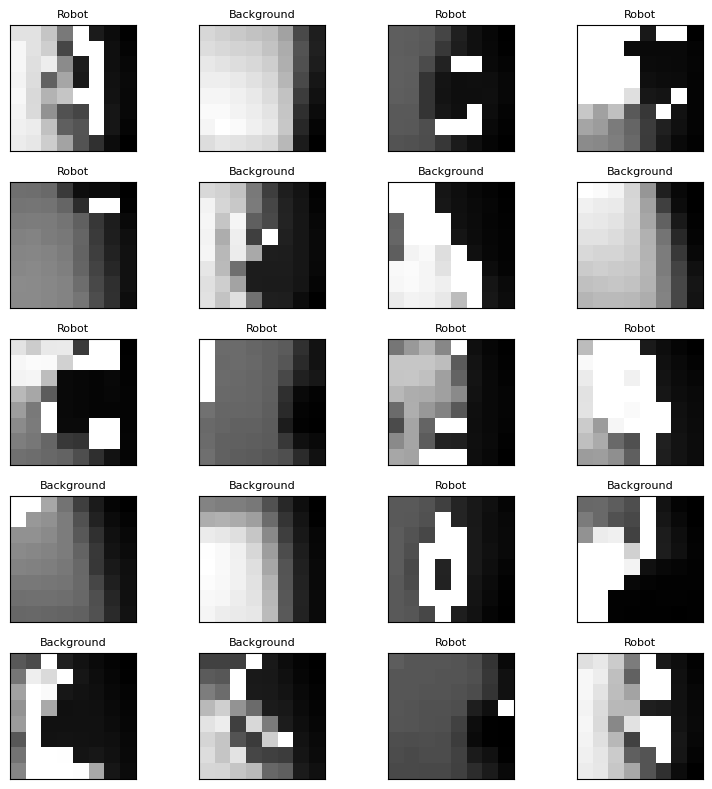

In [12]:
print("Displaying sample images...")
w_vis = 10 # Variables for visualization grid, distinct from image width/height
h_vis = 10
fig = plt.figure(figsize=(8, 8))
columns = 4
rows = 5

num_to_show = min(columns * rows, samples_number)
if samples_number > 0:
    for i in range(1, num_to_show + 1):
        index = random.randint(0, samples_number - 1)
        img = np.array(dataset.data[index]).reshape(8, 8) # 8x8 image
        img = img.astype(float)
        img_max = np.max(img)
        img_norm = img / img_max if img_max > 0 else img # Normalize, handle division by zero
        fig.add_subplot(rows, columns, i)
        plt.imshow(img_norm, cmap='gray')
        plt.xticks([]) # Hide ticks
        plt.yticks([]) # Hide ticks
        label = "Robot" if dataset.target[index] == 1 else "Background"
        plt.title(label, fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("No valid samples available to display.")

## Prepare the dataset for training:

In [13]:
print("Preparing data arrays for training...")
if samples_number > 0:
    # Normalize pixel values to [0, 1]
    X = np.array(dataset.data, dtype=np.float32) / 255.0
    y = np.array(dataset.target)
    print("Shape X (raw): ", X.shape)
    print("Shape y: ", y.shape)
else:
    print("Error: No valid data loaded. Cannot prepare arrays.")
    X, y = np.array([]), np.array([]) # Assign empty arrays

Preparing data arrays for training...
Shape X (raw):  (4150, 64)
Shape y:  (4150,)


## Check class balance

In [14]:
if y.size > 0:
    samples_1 = np.count_nonzero(y == 1)
    samples_0 = np.count_nonzero(y == 0)
    print("Samples number 1 (Robot): ", samples_1)
    print("Samples number 0 (Background): ", samples_0)
    assert samples_1 > 0 and samples_0 > 0, "Warning: One class has zero samples!"
else:
    print("No labels available to check balance.")

Samples number 1 (Robot):  2088
Samples number 0 (Background):  2062


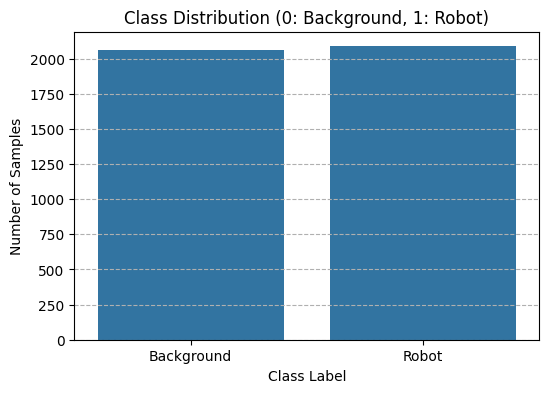

In [15]:
# Visualize Class Balance
if y.size > 0:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=y)
    plt.title('Class Distribution (0: Background, 1: Robot)')
    plt.xlabel('Class Label')
    plt.ylabel('Number of Samples')
    # Use class names if available, otherwise use 0 and 1
    class_names_map = {0: 'Background', 1: 'Robot'}
    plt.xticks(ticks=[0, 1], labels=[class_names_map[0], class_names_map[1]])
    plt.grid(axis='y', linestyle='--')
    plt.show()
else:
    print("No labels available to visualize balance.")

## Get image dimensions

In [16]:
# Reshape data to 8x8 images for consistency and define dimensions
# Note: X is already normalized here. dataset.data is int. We'll reshape X.
if X.shape[0] > 0:
    try:
        X_reshaped = X.reshape(-1, 8, 8)
        height, width = X_reshaped.shape[1], X_reshaped.shape[2]
        number_of_channels = 1 # Grayscale
        print(f"Image dimensions set: height={height}, width={width}, channels={number_of_channels}")
    except ValueError as e:
        print(f"Error reshaping data to 8x8: {e}. Check if all samples have 64 features.")
        # Set default/fallback values or stop execution
        height, width, number_of_channels = 8, 8, 1 # Assuming default if reshape fails but data exists
else:
    print("No data to determine dimensions from.")
    height, width, number_of_channels = 8, 8, 1 # Default values

# Use the reshaped data going forward for splitting
X = X_reshaped

Image dimensions set: height=8, width=8, channels=1


## Splitting dataset

In [17]:
print("Splitting data into training, validation, and test sets...")
if X.shape[0] > 0:
    # Split off test set (15%)
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y, test_size=0.15, random_state=42, stratify=y
    )
    # Split remaining training data into train and validation (15% of *remaining* data for validation)
    # This makes validation ~0.15 * 0.85 = 12.75% of total; Train ~ 72.25%
    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train_full, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full
    )

    print("Shapes after splitting:")
    print(" X_train:", X_train.shape)
    print(" y_train:", y_train.shape)
    print(" X_valid:", X_valid.shape)
    print(" y_valid:", y_valid.shape)
    print(" X_test:", X_test.shape)
    print(" y_test:", y_test.shape)

    # Reshape for CNN input (add channel dimension)
    X_train = X_train.reshape((*X_train.shape, 1))
    X_valid = X_valid.reshape((*X_valid.shape, 1))
    X_test = X_test.reshape((*X_test.shape, 1))
    print("Shapes after adding channel dimension:")
    print(" X_train:", X_train.shape) # Should be (samples, 8, 8, 1)
    print(" X_valid:", X_valid.shape)
    print(" X_test:", X_test.shape)

else:
    print("No data to split.")
    # Assign empty arrays to prevent errors later if needed
    X_train, X_valid, X_test = np.array([]), np.array([]), np.array([])
    y_train, y_valid, y_test = np.array([]), np.array([]), np.array([])

Splitting data into training, validation, and test sets...
Shapes after splitting:
 X_train: (2997, 8, 8)
 y_train: (2997,)
 X_valid: (530, 8, 8)
 y_valid: (530,)
 X_test: (623, 8, 8)
 y_test: (623,)
Shapes after adding channel dimension:
 X_train: (2997, 8, 8, 1)
 X_valid: (530, 8, 8, 1)
 X_test: (623, 8, 8, 1)


# **4. Generalized Evaluation Functions**

In [18]:
def evaluate_model(model, X_test_data, y_test_data):
    """Evaluates a compiled Keras model (binary classification)."""
    print("\n--- Evaluating Model on Test Set ---")
    try:
        loss, accuracy = model.evaluate(X_test_data, y_test_data, verbose=0)
        print(f"Test Loss:     {loss:.4f}")
        print(f"Test Accuracy: {accuracy:.4f}")

        y_pred_prob = model.predict(X_test_data)
        y_pred = (y_pred_prob > 0.5).astype(int).flatten()

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_test_data, y_pred, average='binary', zero_division=0
        )
        print(f"Test Precision: {precision:.4f}")
        print(f"Test Recall:    {recall:.4f}")
        print(f"Test F1-Score:  {f1:.4f}")

        print("\n--- Confusion Matrix ---")
        cm = confusion_matrix(y_test_data, y_pred)
        print(cm)

        # Store results
        results = {
            'loss': loss,
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_score': f1,
            'confusion_matrix': cm
        }
        return results

    except Exception as e:
        print(f"An error occurred during evaluation: {e}")
        return None

def plot_training_history(history):
    """Plots Loss and Accuracy curves from a Keras History object."""
    print("\n--- Training History ---")
    try:
        plt.figure(figsize=(12, 5))

        # Plot Loss
        plt.subplot(1, 2, 1)
        plt.plot(history.history['loss'], 'g', label='Training Loss')
        plt.plot(history.history['val_loss'], color='orange', label='Validation Loss')
        plt.title('Training and Validation Loss')
        plt.ylabel('Loss')
        plt.xlabel('Epoch')
        plt.legend()
        plt.grid(True)

        # Plot Accuracy
        plt.subplot(1, 2, 2)
        plt.plot(history.history['accuracy'], 'g', label='Training Accuracy')
        plt.plot(history.history['val_accuracy'], color='orange', label='Validation Accuracy')
        plt.title('Training and Validation Accuracy')
        plt.ylabel('Accuracy')
        plt.xlabel('Epoch')
        plt.legend()
        plt.grid(True)

        plt.tight_layout()
        plt.show()

    except KeyError as e:
        print(f"Could not plot: Metric '{e}' not found in history. Check model compilation metrics.")
    except Exception as e:
        print(f"An error occurred during plotting: {e}")

def plot_confusion_matrix_single(cm, title="Confusion Matrix"):
     """Plots a single confusion matrix."""
     try:
        fig, ax = plt.subplots(figsize=(6, 5))
        disp = ConfusionMatrixDisplay(confusion_matrix=cm)
        disp.plot(ax=ax, cmap=plt.cm.Blues)
        ax.set_title(title)
        plt.show()
     except NameError:
        print("ConfusionMatrixDisplay not imported? Cannot plot confusion matrix.")
     except Exception as plot_e:
        print(f"Could not plot confusion matrix: {plot_e}")

def print_table(data_dict, headers, title="Model Results"):
    """Prints a simple table from a dictionary."""
    print(f"\n--- {title} ---")
    # Prepare data for tabulate: list of lists
    table_data = [[header, data_dict.get(header, 'N/A')] for header in headers]
    print(tabulate(table_data, tablefmt='grid'))

# **5. Partially Binarized CNN (BNN) using Larq**

Following exploration (removed from this notebook), standard quantization methods and fully binarized models showed limitations or instability. This section implements a **partially binarized CNN** based on the supervisor's guidance.

*   The **first layer** (`Conv2D`) remains **full precision (float32)** to process raw input effectively.
*   The **middle layers** (`QuantConv2D`, `QuantDense`) are **quantized/binarized** using Larq's `ste_sign` (1-bit weights and activations) for model compression. Batch Normalization is used after quantized layers for stability.
*   The **final layer** (`Dense`) remains **full precision (float32)** for stable output calculation.
*   Low learning rate and Early Stopping are used to manage training stability and prevent overfitting.

## BNN Hyperparameters

In [19]:
# Hyperparameters for the BNN training run
# Note: LR and batch size were tuned iteratively.
bnn_learning_rate = 1e-5
bnn_epochs = 300 # Max epochs; EarlyStopping will likely stop sooner
bnn_batch_size = 16 # Kept at 16 as used in the successful run
bnn_early_stopping_patience = 25

print(f"BNN Learning Rate: {bnn_learning_rate}")
print(f"BNN Max Epochs: {bnn_epochs}")
print(f"BNN Batch Size: {bnn_batch_size}")
print(f"BNN Early Stopping Patience: {bnn_early_stopping_patience}")

BNN Learning Rate: 1e-05
BNN Max Epochs: 300
BNN Batch Size: 16
BNN Early Stopping Patience: 25


## BNN Model Definition

In [20]:
# Setup/Define BNN Model

# Ensure Larq is imported from the top cell

print(f"Using Larq version: {lq.__version__}")
print(f"Using TensorFlow version: {tf.__version__}")

# --- Define the CNN Model with Quantized Middle Layers ---
def build_quantized_middle_cnn_model(kernel_size=3):
    quant_kwargs = dict(kernel_quantizer="ste_sign",
                        kernel_constraint="weight_clip")

    model = tf.keras.Sequential(name="Quantized_Middle_CNN")
    # Input checks rely on width, height, number_of_channels defined in Data Prep section
    model.add(tf.keras.layers.InputLayer(input_shape=(width, height, number_of_channels), name="input_layer")) # Ensure dimensions are correct (8, 8, 1)

    # --- Layer 1: Standard Float Conv2D + BN (First Layer = Full Precision) ---
    model.add(tf.keras.layers.Conv2D(32, (kernel_size, kernel_size),
                                     activation='relu', padding="same", name="conv2d_1_float"))
    model.add(tf.keras.layers.BatchNormalization(momentum=0.9, name="batch_norm_1"))
    model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name="max_pooling2d_1")) # Name clarity

    # --- Layer 2: Quantized Conv2D + BN (Added Middle Layer = Quantized) ---
    model.add(lq.layers.QuantConv2D(64, (kernel_size, kernel_size),
                                     padding="same", name="quantconv2d_2", **quant_kwargs)) # Removed activation='relu'
    model.add(tf.keras.layers.BatchNormalization(momentum=0.9, name="batch_norm_2"))
    model.add(tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name="max_pooling2d_2"))

    # Flatten
    model.add(tf.keras.layers.Flatten(name="flatten"))

    # --- Layer 3: Quantized Dense + BN (Middle Layer = Quantized) ---
    model.add(lq.layers.QuantDense(64, name="quant_dense_middle", input_quantizer="ste_sign", **quant_kwargs))
    model.add(tf.keras.layers.BatchNormalization(momentum=0.9, name="batch_norm_3"))

    # --- Layer 4: Standard Float Dense Output (Last Layer = Full Precision) ---
    model.add(tf.keras.layers.Dense(1, activation='sigmoid', name="output_dense_float"))

    return model

print("--- BNN Model function defined (Conv1=F, Conv2=Q, Dense1=Q, Dense2=F) ---")

Using Larq version: 0.13.3
Using TensorFlow version: 2.10.0
--- BNN Model function defined (Conv1=F, Conv2=Q, Dense1=Q, Dense2=F) ---


## BNN Model Compilation

In [21]:
# Build the model instance
bnn_model = build_quantized_middle_cnn_model()

# Compile the model with the chosen low learning rate
bnn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=bnn_learning_rate),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

print("--- Model Summary (Quantized Middle Layers) ---")
bnn_model.summary()
print(f"\n--- BNN Model Instantiated and Compiled (LR={bnn_learning_rate}) ---")

--- Model Summary (Quantized Middle Layers) ---
Model: "Quantized_Middle_CNN"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_1_float (Conv2D)     (None, 8, 8, 32)          320       
                                                                 
 batch_norm_1 (BatchNormaliz  (None, 8, 8, 32)         128       
 ation)                                                          
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 4, 4, 32)         0         
 2D)                                                             
                                                                 
 quantconv2d_2 (QuantConv2D)  (None, 4, 4, 64)         18496     
                                                                 
 batch_norm_2 (BatchNormaliz  (None, 4, 4, 64)         256       
 ation)                                                         

## BNN Model Training

In [22]:
# --- Add Early Stopping Callback ---
early_stopping_cb = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=bnn_early_stopping_patience,
    restore_best_weights=True, # IMPORTANT
    verbose=1
)
# -------------------------------

# Use the bnn_batch_size variable here
print(f"\n--- Starting BNN Training for up to {bnn_epochs} epochs with batch size {bnn_batch_size} (Early Stopping Enabled) ---")

start_time = time.time()
# --- Pass the callback to model.fit (uncommented) and use batch size variable ---
history_bnn = bnn_model.fit(X_train, y_train,
                            epochs=bnn_epochs,
                            batch_size=bnn_batch_size, # Use defined variable
                            validation_data=(X_valid, y_valid),
                            callbacks=[early_stopping_cb], # Use the callback
                            verbose=1)
# ------------------------------------------------------------------------
end_time = time.time()

print(f"--- BNN Training finished in {end_time - start_time:.2f} seconds ---")
if early_stopping_cb.stopped_epoch > 0:
     actual_epochs = early_stopping_cb.stopped_epoch + 1
     print(f"Early stopping triggered after epoch {actual_epochs}")
else:
     actual_epochs = bnn_epochs
     print(f"Training completed full {bnn_epochs} epochs (Early stopping did not trigger).")

# Store actual epochs ran for plotting if needed
# epochs_ran = actual_epochs


--- Starting BNN Training for up to 300 epochs with batch size 16 (Early Stopping Enabled) ---
Epoch 1/300
188/188 [==============================] - 5s 8ms/step - loss: 0.6854 - accuracy: 0.6496 - val_loss: 0.6253 - val_accuracy: 0.7113
Epoch 2/300
188/188 [==============================] - 1s 7ms/step - loss: 0.6034 - accuracy: 0.7027 - val_loss: 0.5569 - val_accuracy: 0.7491
Epoch 3/300
188/188 [==============================] - 1s 6ms/step - loss: 0.5625 - accuracy: 0.7247 - val_loss: 0.5156 - val_accuracy: 0.7679
Epoch 4/300
188/188 [==============================] - 1s 6ms/step - loss: 0.5332 - accuracy: 0.7454 - val_loss: 0.4832 - val_accuracy: 0.7887
Epoch 5/300
188/188 [==============================] - 1s 6ms/step - loss: 0.5180 - accuracy: 0.7521 - val_loss: 0.4525 - val_accuracy: 0.8057
Epoch 6/300
188/188 [==============================] - 1s 5ms/step - loss: 0.4821 - accuracy: 0.7678 - val_loss: 0.4290 - val_accuracy: 0.8264
Epoch 7/300
188/188 [=========================

## BNN Model Evaluation


--- Training History ---


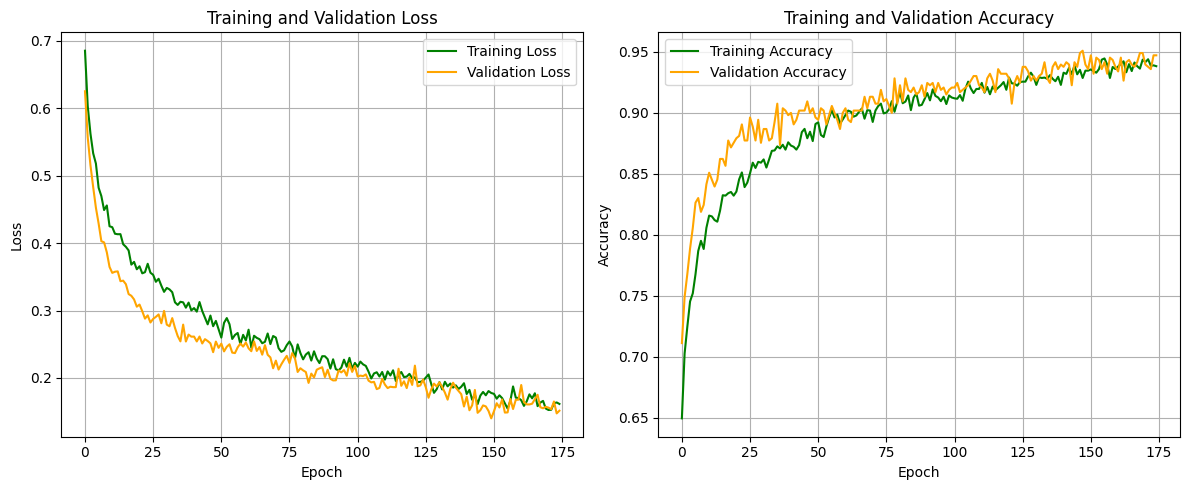


--- Evaluating BNN Model on Test Set ---

--- Evaluating Model on Test Set ---
Test Loss:     0.1397
Test Accuracy: 0.9551
20/20 [==============================] - 0s 1ms/step
Test Precision: 0.9524
Test Recall:    0.9585
Test F1-Score:  0.9554

--- Confusion Matrix ---
[[295  15]
 [ 13 300]]

--- BNN Test Set Performance Summary ---
+-----------+---------+
| Metric    |   Value |
+===========+=========+
| loss      |  0.1397 |
+-----------+---------+
| accuracy  |  0.9551 |
+-----------+---------+
| precision |  0.9524 |
+-----------+---------+
| recall    |  0.9585 |
+-----------+---------+
| f1_score  |  0.9554 |
+-----------+---------+


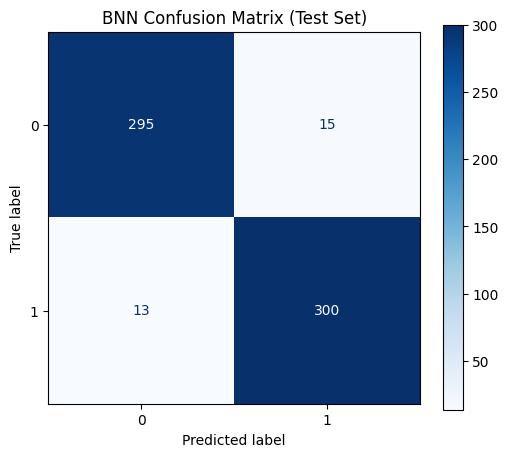

In [23]:
# --- BNN Model Evaluation ---

# 1. Plot training history first
plot_training_history(history_bnn)

# 2. Evaluate on the test set
print("\n--- Evaluating BNN Model on Test Set ---")
# The evaluate_model function prints loss/acc during its run
bnn_results = evaluate_model(bnn_model, X_test, y_test)

# 3. Display results in a table if evaluation was successful
if bnn_results:
    # Prepare data for the table (excluding the matrix itself)
    headers = ['Metric', 'Value']
    table_data = []
    for k, v in bnn_results.items():
        if k != 'confusion_matrix':
             # Format floats nicely
             value_str = f"{v:.4f}" if isinstance(v, (float, np.float32, np.float64)) else str(v)
             table_data.append([k, value_str])

    # Use the print_table function for a tidy summary
    # Note: evaluate_model already prints these, this table is a cleaner summary
    # print_table(dict(table_data), [h[0] for h in table_data], title="BNN Test Set Performance Summary")
    # Instead of the custom print_table, just use tabulate directly on the list of lists
    print("\n--- BNN Test Set Performance Summary ---")
    print(tabulate(table_data, headers=headers, tablefmt='grid'))


    # 4. Plot the confusion matrix using the helper function
    plot_confusion_matrix_single(bnn_results['confusion_matrix'], title="BNN Confusion Matrix (Test Set)")

else:
    print("BNN evaluation failed or produced no results.")

# --- End BNN Model Evaluation ---

## BNN TFLite Conversion

In [24]:
#TFLite Conversion and Saving (using Larq Compute Engine)

print("\n--- Converting BNN Model to TFLite using Larq Compute Engine ---")

try:
    # Define the output path
    tflite_lce_models_dir = pathlib.Path("./tflite_lce_model/")
    tflite_lce_models_dir.mkdir(exist_ok=True)
    tflite_lce_model_path = tflite_lce_models_dir / "lce_cnn_quantized_middle.tflite"

    # Convert the Keras model using LCE
    flatbuffer_bytes = lce.convert_keras_model(bnn_model)

    # Write the flatbuffer file
    with open(tflite_lce_model_path, "wb") as flatbuffer_file:
        flatbuffer_file.write(flatbuffer_bytes)

    print("--- TFLite Conversion with LCE Successful ---")
    print(f"Saved TFLite LCE model to: {tflite_lce_model_path}")

    # Measure size
    lce_model_size_kb = os.path.getsize(tflite_lce_model_path) / float(2**10)
    print(f"TFLite LCE BNN Model Size: {lce_model_size_kb:.2f} KB")

except NameError as e:
     print(f"Conversion failed. Was the model variable 'bnn_model' defined? Error: {e}")
except Exception as e:
    print(f"--- TFLite Conversion with LCE Failed ---")
    print(f"Error: {e}")
    # traceback.print_exc() # Uncomment for detailed traceback

    # Store size for summary
if 'lce_model_size_kb' in locals() and bnn_results:
     bnn_results['tflite_lce_size_kb'] = lce_model_size_kb


--- Converting BNN Model to TFLite using Larq Compute Engine ---


INFO:tensorflow:Assets written to: C:\Users\SMoha\AppData\Local\Temp\tmp58_ule0b\assets


INFO:tensorflow:Assets written to: C:\Users\SMoha\AppData\Local\Temp\tmp58_ule0b\assets


--- TFLite Conversion with LCE Successful ---
Saved TFLite LCE model to: tflite_lce_model\lce_cnn_quantized_middle.tflite
TFLite LCE BNN Model Size: 141.61 KB


# **6. GFLOPS Calculation**

In [25]:
# Calculate GFLOPS for the final BNN model

print("\n--- Calculating FLOPs for BNN Model ---")

def get_flops_tfv2(model):
    # Function needed for TF profiling
    try:
        # Ensure model input shape is correctly inferred or specified
        input_sig = [tf.TensorSpec(shape=(1,) + model.input_shape[1:], dtype=tf.float32)] # Use float32 for profiling sig
        forward_pass = tf.function(model.call, input_signature=input_sig)
        graph_info = profile(forward_pass.get_concrete_function().graph,
                                options=ProfileOptionBuilder.float_operation())
        # The // 2 is an approximation for FMA (fused multiply-add) operations
        flops = graph_info.total_float_ops // 2
        return flops
    except Exception as e:
        print(f"Could not calculate FLOPs: {e}")
        # print("Ensure the model is built and input shape is correct.")
        # traceback.print_exc()
        return None

# Calculate FLOPs for the BNN model
bnn_flops = get_flops_tfv2(bnn_model)

if bnn_flops is not None:
    bnn_gflops = bnn_flops / 1e9 # Convert to GigaFLOPs
    print(f"Estimated BNN Model GFLOPS: {bnn_gflops:.4f}")
else:
    print("FLOPs calculation failed for the BNN model.")

# You could add FLOPs to the results table if desired
# if bnn_results and bnn_flops is not None:
#     bnn_results['GFLOPS'] = f"{bnn_gflops:.4f}"
#     # Re-print table if you modify bnn_results

# Add GFLOPS to the results dictionary if calculated
if bnn_results and bnn_flops is not None:
    bnn_results['gflops'] = f"{bnn_gflops:.4f}" # Store as string for table consistency
elif bnn_results:
    bnn_results['gflops'] = "N/A"


--- Calculating FLOPs for BNN Model ---
Instructions for updating:
Use `tf.compat.v1.graph_util.tensor_shape_from_node_def_name`


Instructions for updating:
Use `tf.compat.v1.graph_util.tensor_shape_from_node_def_name`


Estimated BNN Model GFLOPS: 0.0003


In [26]:
# --- Final BNN Model Summary ---
print("\n--- Final BNN Model Summary ---")

if 'bnn_results' in locals() and bnn_results:
    summary_headers = ['Metric', 'Value']
    summary_metrics = ['accuracy', 'f1_score', 'tflite_lce_size_kb', 'gflops']
    summary_data = []

    for metric in summary_metrics:
        value = bnn_results.get(metric, 'N/A')
        # Format floats nicely if they haven't been formatted already
        if isinstance(value, (float, np.float32, np.float64)):
             value_str = f"{value:.4f}"
        else:
             value_str = str(value)
        # Add units where appropriate
        if metric == 'tflite_lce_size_kb' and value != 'N/A':
            value_str += " KB"
        elif metric == 'gflops' and value != 'N/A':
             value_str += " GFLOPS"

        summary_data.append([metric.replace('_', ' ').title(), value_str])

    print(tabulate(summary_data, headers=summary_headers, tablefmt='grid'))
else:
    print("Could not generate final summary. Ensure BNN evaluation completed.")


--- Final BNN Model Summary ---
+--------------------+---------------+
| Metric             | Value         |
+====================+===============+
| Accuracy           | 0.9551        |
+--------------------+---------------+
| F1 Score           | 0.9554        |
+--------------------+---------------+
| Tflite Lce Size Kb | 141.6055 KB   |
+--------------------+---------------+
| Gflops             | 0.0003 GFLOPS |
+--------------------+---------------+


# **7. Conclusion**


In [29]:
from IPython.display import display, Markdown

# --- Generate Conclusion ---

# Make sure these variables exist from previous cells
# Example values - replace with actual calculated values
actual_epochs = 145 # Get this from early_stopping_cb.stopped_epoch + 1 if applicable
bnn_results = bnn_results # Assuming this exists from the evaluation cell

if 'bnn_results' in locals() and bnn_results:
    accuracy_val = bnn_results.get('accuracy', 'N/A')
    f1_score_val = bnn_results.get('f1_score', 'N/A')
    size_val = bnn_results.get('tflite_lce_size_kb', 'N/A')
    gflops_val = bnn_results.get('gflops', 'N/A') # Should already be a string if added correctly

    # Format numbers if they are numeric and not 'N/A'
    accuracy_str = f"{accuracy_val:.4f}" if isinstance(accuracy_val, (float, np.float32)) else str(accuracy_val)
    f1_score_str = f"{f1_score_val:.4f}" if isinstance(f1_score_val, (float, np.float32)) else str(f1_score_val)
    size_str = f"{size_val:.2f}" if isinstance(size_val, (float, np.float32)) else str(size_val)
    gflops_str = str(gflops_val) # Already formatted or 'N/A'

    conclusion_text = f"""

This notebook loaded Time-of-Flight sensor data (8x8 depth images) and trained a partially binarized Convolutional Neural Network (CNN) using the Larq library to classify images as 'Background' or 'Robot'.

The final model architecture keeps the first convolutional layer and the final output layer in full precision (float32), while quantizing the middle convolutional and dense layers to 1-bit precision (weights and activations) using the STE sign quantizer.

Training employed a low learning rate (1e-5) and Early Stopping (stopped after {actual_epochs} epochs) to ensure stability and prevent overfitting. The model achieved the following on the test set:
*   **Accuracy:** {accuracy_str}
*   **F1-Score:** {f1_score_str}

The model was successfully converted to TFLite format using the Larq Compute Engine, resulting in a size of **~{size_str} KB**, making it suitable for potential deployment on edge devices. The estimated computational cost was **~{gflops_str} GFLOPS**.
    """
    display(Markdown(conclusion_text))
else:
    print("Error: Could not generate conclusion because bnn_results was not found.")



This notebook loaded Time-of-Flight sensor data (8x8 depth images) and trained a partially binarized Convolutional Neural Network (CNN) using the Larq library to classify images as 'Background' or 'Robot'.

The final model architecture keeps the first convolutional layer and the final output layer in full precision (float32), while quantizing the middle convolutional and dense layers to 1-bit precision (weights and activations) using the STE sign quantizer.

Training employed a low learning rate (1e-5) and Early Stopping (stopped after 145 epochs) to ensure stability and prevent overfitting. The model achieved the following on the test set:
*   **Accuracy:** 0.9551
*   **F1-Score:** 0.9554

The model was successfully converted to TFLite format using the Larq Compute Engine, resulting in a size of **~141.61 KB**, making it suitable for potential deployment on edge devices. The estimated computational cost was **~0.0003 GFLOPS**.
    